<a href="https://colab.research.google.com/github/Bachbean/Predicting-the-Unpredictable/blob/main/scripts/Plasma_ami.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Column 1: tau = 105
Column 2: tau = 137
Column 3: tau = 98


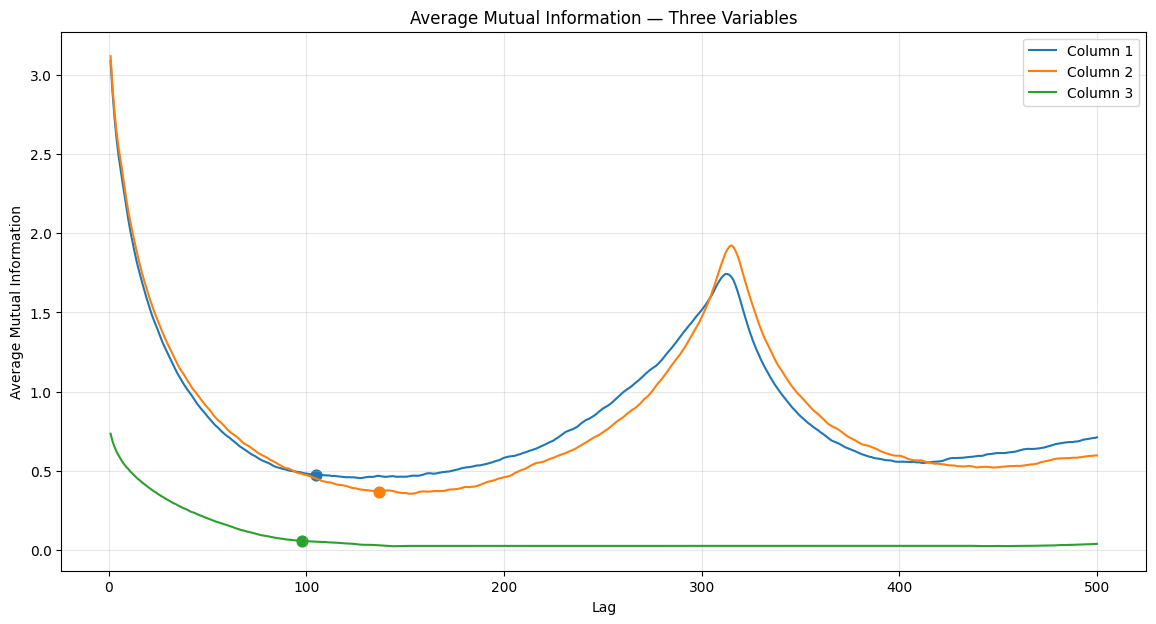


Tau values:
[np.int64(105), np.int64(137), np.int64(98)]


In [ ]:
import numpy as np
import requests
from io import StringIO


url = "https://raw.githubusercontent.com/Bachbean/Predicting-the-Unpredictable/refs/heads/main/data/plasma_states.txt"


# ============================================================
# DOWNLOAD TXT FILE
# ============================================================

response = requests.get(url)
response.raise_for_status()

raw_text = response.text


# ============================================================
# IGNORE FIRST LINE AND DETECT SEPARATOR
# ============================================================

lines = raw_text.splitlines()

# Ignore the first line
data_lines = lines[1:]

# Find first non-empty data line
first_data_line = next(
    line for line in data_lines
    if line.strip()
)

# Automatically determine whether numbers are comma-separated
# or whitespace-separated
delimiter = "," if "," in first_data_line else None


# ============================================================
# LOAD NUMERICAL DATA
# ============================================================

data = np.loadtxt(
    StringIO(raw_text),
    dtype=np.float64,
    skiprows=1,
    delimiter=delimiter
)


# Make sure there are exactly three columns
if data.ndim != 2 or data.shape[1] != 3:
    raise ValueError(
        "Expected exactly three numerical columns."
    )


# ============================================================
# SPLIT INTO THREE ARRAYS
# ============================================================

data1 = data[:, 0]
data2 = data[:, 1]
data3 = data[:, 2]


all_data = [
    data1,
    data2,
    data3
]


# ============================================================
# 3. SETTINGS
# ============================================================

max_lag = 500

num_bins = 32


# ============================================================
# 4. MUTUAL INFORMATION FUNCTION
# ============================================================

def mutual_information(x, y, bins):

    joint_hist, _, _ = np.histogram2d(
        x,
        y,
        bins=bins
    )

    joint_prob = (
        joint_hist
        /
        np.sum(joint_hist)
    )

    prob_x = np.sum(
        joint_prob,
        axis=1
    )

    prob_y = np.sum(
        joint_prob,
        axis=0
    )

    expected = (
        prob_x[:, None]
        *
        prob_y[None, :]
    )

    valid = (
        (joint_prob > 0)
        &
        (expected > 0)
    )

    mi = np.sum(
        joint_prob[valid]
        *
        np.log(
            joint_prob[valid]
            /
            expected[valid]
        )
    )

    return mi


# ============================================================
# 5. CALCULATE AMI FOR ALL THREE VARIABLES
# ============================================================

lags = np.arange(
    1,
    max_lag + 1
)

ami_by_column = []

tau_by_column = []


for column, series in enumerate(
    all_data,
    start=1
):

    ami_values = []

    for lag in lags:

        x = series[:-lag]
        y = series[lag:]

        mi = mutual_information(
            x,
            y,
            bins=num_bins
        )

        ami_values.append(mi)


    ami_values = np.asarray(
        ami_values
    )

    ami_by_column.append(
        ami_values
    )


    # Find first local minimum
    first_minimum = None

    for i in range(
        1,
        len(ami_values) - 1
    ):

        if (
            ami_values[i] < ami_values[i - 1]
            and
            ami_values[i] < ami_values[i + 1]
        ):

            first_minimum = lags[i]
            break


    tau_by_column.append(
        first_minimum
    )


    print(
        f"Column {column}: "
        f"tau = {first_minimum}"
    )


# ============================================================
# 6. PLOT ALL THREE AMI CURVES
# ============================================================

plt.figure(
    figsize=(14, 7)
)


for column in range(3):

    values = ami_by_column[column]

    plt.plot(
        lags,
        values,
        label=f"Column {column + 1}"
    )


    tau = tau_by_column[column]


    if tau is not None:

        plt.scatter(
            tau,
            values[tau - 1],
            s=60
        )


plt.xlabel("Lag")

plt.ylabel(
    "Average Mutual Information"
)

plt.title(
    "Average Mutual Information — Three Variables"
)

plt.grid(alpha=0.3)

plt.legend()

plt.show()


# ============================================================
# 7. FINAL TAU VALUES
# ============================================================

print("\nTau values:")
print(tau_by_column)